# 01 — Delivery SLA Breach, ETA Regression & CQR Intervals: EDA & Model Benchmark
Benchmarks 5 classifiers (`is_late`), 5 point regressors (`delivery_days`), and 3 Conformalized Quantile Regression (CQR) models (`p10`/`p50`/`p90`) on the real Olist Brazilian E-Commerce dataset, with zoomed operating-region charts and a business cost simulator.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier, CatBoostRegressor
from lightgbm import LGBMClassifier, LGBMRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    mean_absolute_error,
    precision_recall_curve,
    precision_score,
    r2_score,
    recall_score,
    root_mean_squared_error,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier, XGBRegressor

sys.path.append(str(Path.cwd().parent))
from train import (
    ARTIFACTS_DIR,
    load_contract,
    load_olist_dataset,
    make_synthetic_logistics_data,
    resolve_olist_dir,
)

# Unified standard matplotlib color cycle (C0-C4) per model family across all charts
MODEL_COLORS = {
    "LightGBM": "C0", "LGBMRegressor": "C0", "LightGBM-CQR": "C0",
    "RandomForest": "C1", "RandomForestReg": "C1",
    "CatBoost": "C2", "CatBoostReg": "C2", "CatBoost-CQR": "C2",
    "XGBoost": "C3", "XGBRegressor": "C3", "XGBoost-CQR": "C3",
    "LogisticRegression": "C4", "Ridge": "C4",
}

contract, schema_hash = load_contract()
feature_cols = [f["name"] for f in contract["features"]]

olist_dir = resolve_olist_dir()
if olist_dir is not None:
    dataset_label = "Real Olist E-Commerce Dataset"
    df = load_olist_dataset(olist_dir)
    train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["is_late"], random_state=42)

    # Leak-free target encoding: compute seller_late_rate strictly on train_df
    seller_stats = train_df.groupby("seller_id")["is_late"].agg(["mean", "count"])
    valid_sellers = seller_stats[seller_stats["count"] >= 5]["mean"]
    train_df, test_df = train_df.copy(), test_df.copy()
    train_df["seller_late_rate"] = train_df["seller_id"].map(valid_sellers).astype(np.float32)
    test_df["seller_late_rate"] = test_df["seller_id"].map(valid_sellers).astype(np.float32)
else:
    dataset_label = "Synthetic Logistics Dataset"
    df = make_synthetic_logistics_data()
    train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["is_late"], random_state=42)

X_train, X_test = train_df[feature_cols].astype(np.float32), test_df[feature_cols].astype(np.float32)
y_train, y_test = train_df["is_late"].values, test_df["is_late"].values
y_reg_train, y_reg_test = train_df["delivery_days"].values, test_df["delivery_days"].values

print(f"Dataset: {dataset_label} (schema_hash={schema_hash})")
print(f"Train rows: {len(X_train):,} | Test rows: {len(X_test):,} | Late rate: {y_test.mean():.2%} | Mean ETA: {y_reg_test.mean():.2f}d")
print("\nMissing values in test split:")
print(X_test.isna().mean().map("{:.2%}".format))

Dataset: Real Olist E-Commerce Dataset (schema_hash=fe66b8873d6c)
Train rows: 76,793 | Test rows: 19,199 | Late rate: 8.10% | Mean ETA: 12.43d

Missing values in test split:
distance_km         0.00%
weight_grams        0.00%
seller_late_rate    4.11%
is_weekend          0.00%
freight_ratio       0.00%
dtype: str


In [ ]:
# 1. Classification Benchmark (is_late)
lr = LogisticRegression(max_iter=500).fit(X_train.fillna(0.0), y_train)
rf_m = RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=42).fit(X_train, y_train)
cb_m = CatBoostClassifier(iterations=300, depth=6, learning_rate=0.08, random_seed=42, verbose=0, allow_writing_files=False).fit(X_train, y_train)
xgb_m = XGBClassifier(n_estimators=120, max_depth=5, learning_rate=0.08, random_state=42).fit(X_train, y_train)
lgb_m = LGBMClassifier(n_estimators=120, num_leaves=31, learning_rate=0.08, random_state=42, verbose=-1).fit(X_train, y_train)

probs = {
    "LogisticRegression": lr.predict_proba(X_test.fillna(0.0))[:, 1],
    "RandomForest": rf_m.predict_proba(X_test)[:, 1],
    "CatBoost": cb_m.predict_proba(X_test)[:, 1],
    "XGBoost": xgb_m.predict_proba(X_test)[:, 1],
    "LightGBM": np.asarray(lgb_m.predict_proba(X_test))[:, 1],
}

t = contract["threshold"]
rows = []
for name, p in probs.items():
    preds = (p >= t).astype(int)
    rows.append({
        "Model": name,
        "PR-AUC": round(average_precision_score(y_test, p), 4),
        "Precision": round(precision_score(y_test, preds, zero_division=0), 4),
        "Recall": round(recall_score(y_test, preds, zero_division=0), 4),
        "F1": round(f1_score(y_test, preds, zero_division=0), 4),
    })
pd.DataFrame(rows).sort_values("PR-AUC", ascending=False)

,Model,PR-AUC,Precision,Recall,F1
1,RandomForest,0.1316,0.1414,0.3537,0.2021
4,LightGBM,0.1288,0.1402,0.3614,0.2020
2,CatBoost,0.1288,0.1380,0.3402,0.1964
3,XGBoost,0.1279,0.1381,0.3550,0.1988
0,LogisticRegression,0.0975,0.1364,0.1164,0.1256


Saved chart to /home/gun/work/github.com/gunawanwijaya/apprentice/01-delivery-sla-breach/artifacts/pr_curve_threshold.png


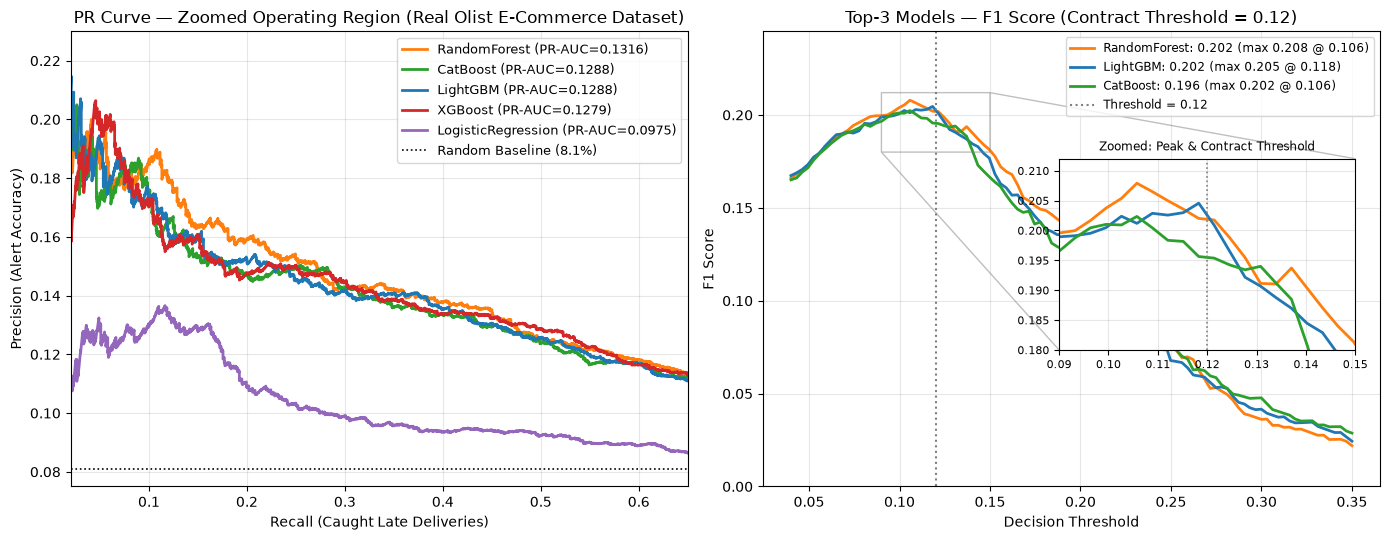

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Sort all models descending by PR-AUC
ranked = sorted(
    [(name, p, average_precision_score(y_test, p)) for name, p in probs.items()],
    key=lambda x: x[2],
    reverse=True,
)

# Left: Zoomed Precision-Recall Curve (legend sorted by PR-AUC)
base_rate = y_test.mean()
for name, p, ap in ranked:
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(rec, prec, lw=2, color=MODEL_COLORS[name], label=f"{name} (PR-AUC={ap:.4f})")

axes[0].axhline(base_rate, color="black", linestyle=":", lw=1.2, label=f"Random Baseline ({base_rate:.1%})")
axes[0].set_title(f"PR Curve — Zoomed Operating Region ({dataset_label})")
axes[0].set_xlabel("Recall (Caught Late Deliveries)")
axes[0].set_ylabel("Precision (Alert Accuracy)")
axes[0].set_xlim(0.02, 0.65)
axes[0].set_ylim(0.075, 0.23)
axes[0].legend(loc="upper right", fontsize=9)
axes[0].grid(alpha=0.3)

# Right: Top-3 Models F1 Threshold Tuning + Zoomed Inset around Peak (0.09 - 0.15)
thresholds = np.linspace(0.04, 0.35, 100)
t_contract = contract["threshold"]

top3 = sorted(
    ranked[:3],
    key=lambda x: f1_score(y_test, x[1] >= t_contract, zero_division=0),
    reverse=True,
)

ax_ins = axes[1].inset_axes([0.48, 0.30, 0.48, 0.42])

for name, p, _ in top3:
    f1s = [f1_score(y_test, p >= th, zero_division=0) for th in thresholds]
    f1_at_t = f1_score(y_test, p >= t_contract, zero_division=0)
    peak_idx = int(np.argmax(f1s))
    axes[1].plot(
        thresholds,
        f1s,
        lw=2.0,
        color=MODEL_COLORS[name],
        label=f"{name}: {f1_at_t:.3f} (max {f1s[peak_idx]:.3f} @ {thresholds[peak_idx]:.3f})",
    )
    ax_ins.plot(thresholds, f1s, lw=2.0, color=MODEL_COLORS[name])

axes[1].axvline(t_contract, color="gray", linestyle=":", lw=1.5, label=f"Threshold = {t_contract}")
axes[1].set_title(f"Top-3 Models — F1 Score (Contract Threshold = {t_contract})")
axes[1].set_xlabel("Decision Threshold")
axes[1].set_ylabel("F1 Score")
axes[1].set_ylim(0.0, 0.245)
axes[1].legend(loc="upper right", fontsize=8.5)
axes[1].grid(alpha=0.3)

# Configure zoomed inset around peak F1 & contract threshold
ax_ins.axvline(t_contract, color="gray", linestyle=":", lw=1.2)
ax_ins.set_xlim(0.09, 0.15)
ax_ins.set_ylim(0.180, 0.212)
ax_ins.set_title("Zoomed: Peak & Contract Threshold", fontsize=8.5)
ax_ins.tick_params(labelsize=8)
ax_ins.grid(alpha=0.3)
axes[1].indicate_inset_zoom(ax_ins, edgecolor="gray", alpha=0.5)

plt.tight_layout()
out_img = ARTIFACTS_DIR / "pr_curve_threshold.png"
plt.savefig(out_img, dpi=150)
print(f"Saved chart to {out_img}")
plt.show()

In [4]:
# Business Cost Simulator (Top 3 models):
# False Positive (unnecessary carrier reroute = $2) vs False Negative (late SLA refund/churn = $15)
COST_FP, COST_FN = 2.0, 15.0

summary_rows = []
for name, p, _ in ranked[:3]:
    best = None
    for th in thresholds:
        preds = (p >= th).astype(int)
        fp = int(((preds == 1) & (y_test == 0)).sum())
        fn = int(((preds == 0) & (y_test == 1)).sum())
        total_cost = fp * COST_FP + fn * COST_FN
        if best is None or total_cost < best["total_cost_usd"]:
            best = {
                "Model": name,
                "best_threshold": round(float(th), 3),
                "FP": fp,
                "FN": fn,
                "total_cost_usd": total_cost,
            }
    summary_rows.append(best)

cost_summary = pd.DataFrame(summary_rows).sort_values("total_cost_usd")
cost_summary

,Model,best_threshold,FP,FN,total_cost_usd
2,LightGBM,0.118,3553,973,21701.0
0,RandomForest,0.121,3249,1016,21738.0
1,CatBoost,0.131,2597,1109,21829.0


In [5]:
# 2. ETA Regression Benchmark (delivery_days)
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X_train.fillna(0.0), y_reg_train)
rf_r = RandomForestRegressor(n_estimators=150, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=42).fit(X_train, y_reg_train)
cb_r = CatBoostRegressor(iterations=300, depth=6, learning_rate=0.08, random_seed=42, verbose=0, allow_writing_files=False).fit(X_train, y_reg_train)
xgb_r = XGBRegressor(n_estimators=120, max_depth=5, learning_rate=0.08, random_state=42).fit(X_train, y_reg_train)
lgb_r = LGBMRegressor(n_estimators=120, num_leaves=31, learning_rate=0.08, random_state=42, verbose=-1).fit(X_train, y_reg_train)

reg_preds = {
    "Ridge": ridge.predict(X_test.fillna(0.0)),
    "RandomForestReg": rf_r.predict(X_test),
    "CatBoostReg": cb_r.predict(X_test),
    "XGBRegressor": xgb_r.predict(X_test),
    "LGBMRegressor": lgb_r.predict(X_test),
}

reg_rows = []
for name, pr in reg_preds.items():
    reg_rows.append({
        "Regressor": name,
        "MAE (days)": round(float(mean_absolute_error(y_reg_test, pr)), 4),
        "RMSE (days)": round(float(root_mean_squared_error(y_reg_test, pr)), 4),
        "R2": round(float(r2_score(y_reg_test, pr)), 4),
    })
reg_df = pd.DataFrame(reg_rows).sort_values("MAE (days)", ascending=True)
reg_df

,Regressor,MAE (days),RMSE (days),R2
4,LGBMRegressor,5.1377,7.4689,0.2656
1,RandomForestReg,5.1411,7.4823,0.2629
3,XGBRegressor,5.1470,7.4833,0.2627
2,CatBoostReg,5.1587,7.4975,0.2599
0,Ridge,5.4283,7.8027,0.1984


Saved chart to /home/gun/work/github.com/gunawanwijaya/apprentice/01-delivery-sla-breach/artifacts/eta_regression_eval.png


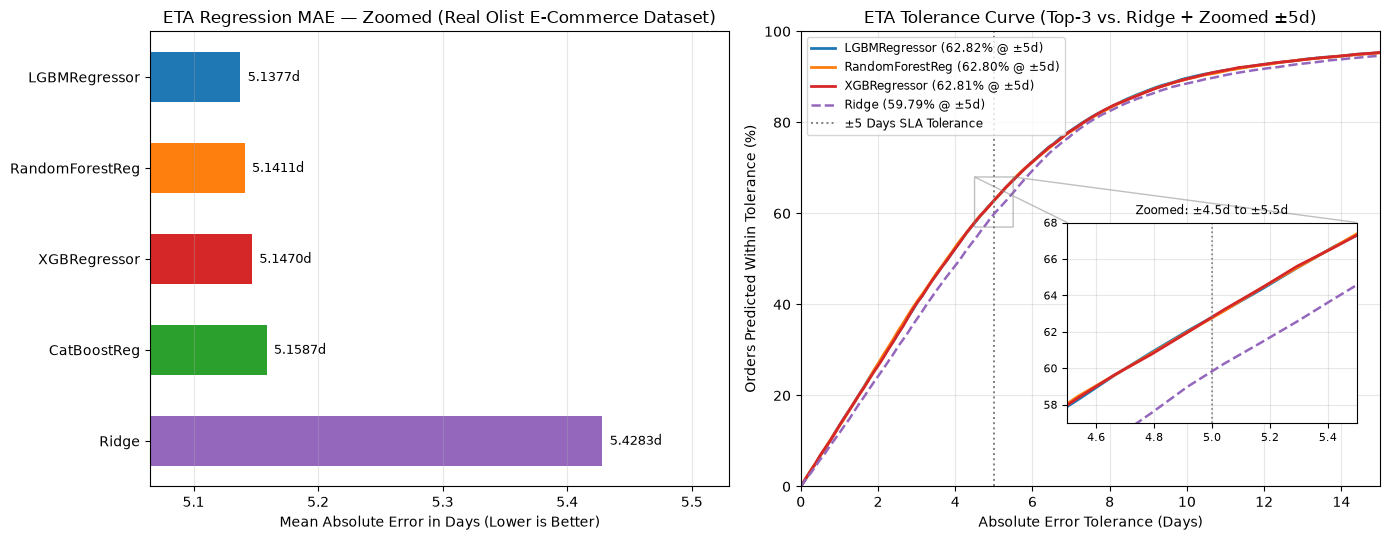

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: Zoomed MAE Comparison (unified per-model colors)
min_mae, max_mae = reg_df["MAE (days)"].min(), reg_df["MAE (days)"].max()
pad = max((max_mae - min_mae) * 0.25, 0.05)
bar_colors = [MODEL_COLORS[name] for name in reg_df["Regressor"]]
bars = axes[0].barh(reg_df["Regressor"], reg_df["MAE (days)"], color=bar_colors, height=0.55)
axes[0].invert_yaxis()
axes[0].set_xlim(min_mae - pad, max_mae + pad * 1.4)
for bar, val in zip(bars, reg_df["MAE (days)"]):
    axes[0].text(val + pad * 0.08, bar.get_y() + bar.get_height() / 2, f"{val:.4f}d", va="center", fontsize=9)
axes[0].set_title(f"ETA Regression MAE — Zoomed ({dataset_label})")
axes[0].set_xlabel("Mean Absolute Error in Days (Lower is Better)")
axes[0].grid(axis="x", alpha=0.3)

# Right: Top-3 Regressors + Ridge Baseline with Zoomed Inset around ±5d
err_grid = np.linspace(0, 15, 120)
ax_ins = axes[1].inset_axes([0.46, 0.14, 0.50, 0.44])

plot_models = list(reg_df["Regressor"].head(3)) + ["Ridge"]
for name in plot_models:
    abs_err = np.abs(y_reg_test - reg_preds[name])
    within_pct = [(abs_err <= d).mean() * 100 for d in err_grid]
    within_5d = (abs_err <= 5.0).mean() * 100
    col = MODEL_COLORS[name]
    style = dict(lw=1.8, linestyle="--", color=col) if name == "Ridge" else dict(lw=2.0, color=col)
    axes[1].plot(err_grid, within_pct, label=f"{name} ({within_5d:.2f}% @ ±5d)", **style)
    ax_ins.plot(err_grid, within_pct, **style)

axes[1].axvline(5.0, color="gray", linestyle=":", lw=1.4, label="±5 Days SLA Tolerance")
axes[1].set_title("ETA Tolerance Curve (Top-3 vs. Ridge + Zoomed ±5d)")
axes[1].set_xlabel("Absolute Error Tolerance (Days)")
axes[1].set_ylabel("Orders Predicted Within Tolerance (%)")
axes[1].set_xlim(0, 15)
axes[1].set_ylim(0, 100)
axes[1].legend(loc="upper left", fontsize=8.5)
axes[1].grid(alpha=0.3)

# Configure zoomed inset around ±5 days
ax_ins.axvline(5.0, color="gray", linestyle=":", lw=1.2)
ax_ins.set_xlim(4.5, 5.5)
ax_ins.set_ylim(57, 68)
ax_ins.set_title("Zoomed: ±4.5d to ±5.5d", fontsize=8.5)
ax_ins.tick_params(labelsize=8)
ax_ins.grid(alpha=0.3)
axes[1].indicate_inset_zoom(ax_ins, edgecolor="gray", alpha=0.5)

plt.tight_layout()
out_reg = ARTIFACTS_DIR / "eta_regression_eval.png"
plt.savefig(out_reg, dpi=150)
print(f"Saved chart to {out_reg}")
plt.show()

In [7]:
# 3. Conformalized Quantile Regression (CQR) Benchmark (p10 / p50 / p90)
coverage_target = float(contract.get("eta_coverage_target", 0.80))
alpha_low = (1.0 - coverage_target) / 2.0
alpha_high = 1.0 - alpha_low

X_fit, X_cal, y_fit, y_cal = train_test_split(X_train, y_reg_train, test_size=0.2, random_state=42)

cqr_builders = [
    ("LightGBM-CQR", lambda q: LGBMRegressor(objective="quantile", alpha=q, n_estimators=120, num_leaves=31, learning_rate=0.08, random_state=42, verbose=-1)),
    ("CatBoost-CQR", lambda q: CatBoostRegressor(loss_function=f"Quantile:alpha={q}", iterations=300, depth=6, learning_rate=0.08, random_seed=42, verbose=0, allow_writing_files=False)),
    ("XGBoost-CQR", lambda q: XGBRegressor(objective="reg:quantileerror", quantile_alpha=q, n_estimators=120, max_depth=5, learning_rate=0.08, random_state=42)),
]

cqr_rows, cqr_artifacts = [], {}
for name, build_fn in cqr_builders:
    qm = {lbl: build_fn(a).fit(X_fit, y_fit) for lbl, a in [("p10", alpha_low), ("p50", 0.50), ("p90", alpha_high)]}
    scores = np.maximum(qm["p10"].predict(X_cal) - y_cal, y_cal - qm["p90"].predict(X_cal))
    q_margin = float(np.quantile(scores, min(1.0, coverage_target * (1.0 + 1.0 / len(scores)))))

    raw_lo, raw_p50, raw_hi = qm["p10"].predict(X_test), qm["p50"].predict(X_test), qm["p90"].predict(X_test)
    cqr_lo = np.maximum(1.0, raw_lo - q_margin)
    cqr_hi = np.maximum(cqr_lo, raw_hi + q_margin)

    cqr_artifacts[name] = {"lo": cqr_lo, "p50": np.clip(raw_p50, cqr_lo, cqr_hi), "hi": cqr_hi}
    cqr_rows.append({
        "CQR Model": name,
        "Raw Cov (%)": round(float(((y_reg_test >= raw_lo) & (y_reg_test <= raw_hi)).mean()) * 100, 2),
        "CQR Cov (%)": round(float(((y_reg_test >= cqr_lo) & (y_reg_test <= cqr_hi)).mean()) * 100, 2),
        "Q Margin (d)": round(q_margin, 3),
        "Avg Width (d)": round(float((cqr_hi - cqr_lo).mean()), 3),
        "p50 MAE (d)": round(float(mean_absolute_error(y_reg_test, raw_p50)), 3),
    })

cqr_df = pd.DataFrame(cqr_rows).sort_values("Avg Width (d)")
cqr_df

,CQR Model,Raw Cov (%),CQR Cov (%),Q Margin (d),Avg Width (d),p50 MAE (d)
0,LightGBM-CQR,78.37,79.50,0.114,15.105,4.885
1,CatBoost-CQR,78.68,79.56,0.079,15.173,4.902
2,XGBoost-CQR,80.52,79.55,-0.092,15.451,4.958


Saved chart to /home/gun/work/github.com/gunawanwijaya/apprentice/01-delivery-sla-breach/artifacts/cqr_interval_eval.png


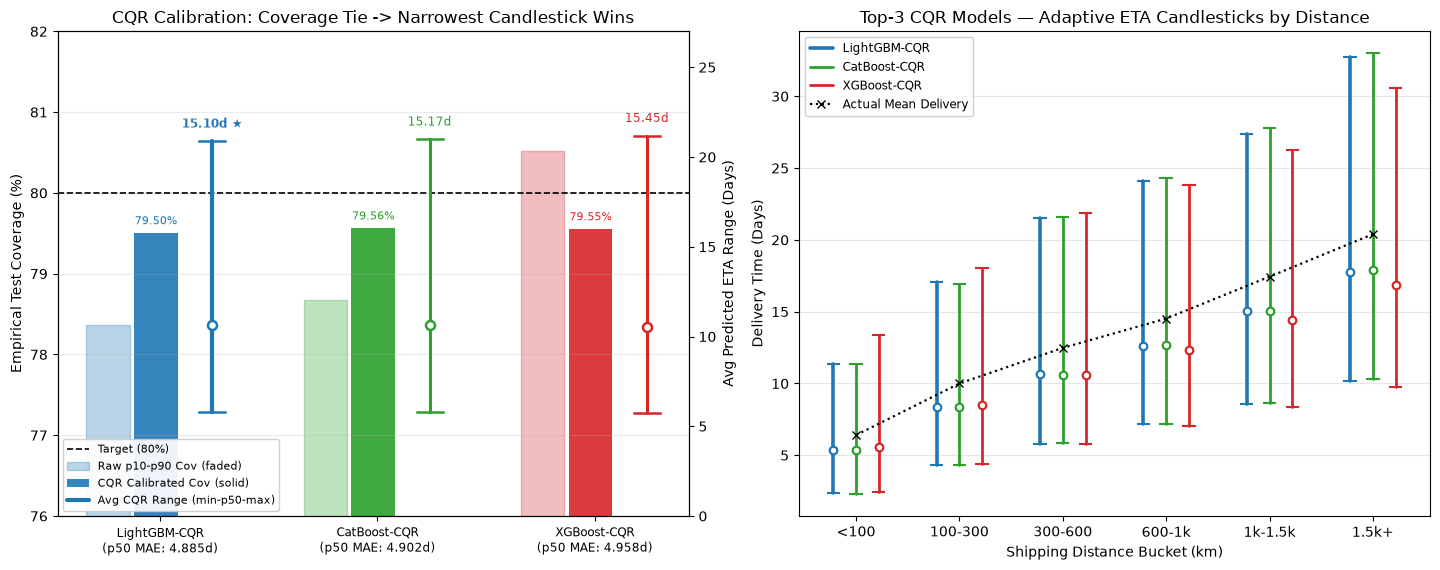

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8))

# --- Left Panel: Dual Y-Axis (Coverage Bars + Global ETA Range Candlestick) ---
ax_cov = axes[0]
ax_eta = ax_cov.twinx()

x = np.arange(len(cqr_df))
w = 0.20
candle_x = x + 0.24

ax_cov.axhline(coverage_target * 100, color="black", linestyle="--", lw=1.2, label=f"Target ({coverage_target:.0%})")

for i, (_, row) in enumerate(cqr_df.iterrows()):
    name = row["CQR Model"]
    col = MODEL_COLORS[name]
    is_best = i == 0

    # Left Y-Axis: Raw (faded) vs. CQR Calibrated (solid) in the model's unified color
    ax_cov.bar(x[i] - 0.24, row["Raw Cov (%)"], width=w, color=col, alpha=0.30, edgecolor=col,
               label="Raw p10-p90 Cov (faded)" if i == 0 else None)
    ax_cov.bar(x[i] - 0.02, row["CQR Cov (%)"], width=w, color=col, alpha=0.90,
               label="CQR Calibrated Cov (solid)" if i == 0 else None)
    ax_cov.text(x[i] - 0.02, row["CQR Cov (%)"] + 0.08, f"{row['CQR Cov (%)']:.2f}%", ha="center", va="bottom", fontsize=7.8, color=col)

    # Right Y-Axis: Global ETA Range Candlestick in the same unified color
    art = cqr_artifacts[name]
    lo_m, p50_m, hi_m = float(art["lo"].mean()), float(art["p50"].mean()), float(art["hi"].mean())
    width_m = hi_m - lo_m

    ax_eta.plot([candle_x[i], candle_x[i]], [lo_m, hi_m], color=col, lw=3.0 if is_best else 2.2, solid_capstyle="round",
                label="Avg CQR Range (min-p50-max)" if i == 0 else None)
    ax_eta.plot([candle_x[i] - 0.06, candle_x[i] + 0.06], [lo_m, lo_m], color=col, lw=1.8)
    ax_eta.plot([candle_x[i] - 0.06, candle_x[i] + 0.06], [hi_m, hi_m], color=col, lw=1.8)
    ax_eta.scatter([candle_x[i]], [p50_m], color="#ffffff", edgecolor=col, s=42, zorder=5, lw=1.8)

    tag = f"{width_m:.2f}d" + (" ★" if is_best else "")
    ax_eta.text(candle_x[i], hi_m + 0.6, tag, ha="center", va="bottom", fontsize=8.5,
                fontweight="bold" if is_best else "normal", color=col)

ax_cov.set_xticks(x)
ax_cov.set_xticklabels([f"{m}\n(p50 MAE: {mae:.3f}d)" for m, mae in zip(cqr_df["CQR Model"], cqr_df["p50 MAE (d)"])], fontsize=8.8)
ax_cov.set_ylim(76, 82.0)
ax_eta.set_ylim(0, 27)
ax_cov.set_ylabel("Empirical Test Coverage (%)")
ax_eta.set_ylabel("Avg Predicted ETA Range (Days)")
ax_cov.set_title("CQR Calibration: Coverage Tie -> Narrowest Candlestick Wins")
ax_cov.grid(axis="y", alpha=0.25)

h1, l1 = ax_cov.get_legend_handles_labels()
h2, l2 = ax_eta.get_legend_handles_labels()
ax_cov.legend(h1 + h2, l1 + l2, loc="lower left", fontsize=7.8, framealpha=0.92)

# --- Right Panel: Grouped Candlesticks per Distance Bucket (All 3 Models) ---
ax_b = axes[1]
bins = [0, 100, 300, 600, 1000, 1500, 3500]
labels = ["<100", "100-300", "300-600", "600-1k", "1k-1.5k", "1.5k+"]
dist_bins = pd.cut(X_test["distance_km"].values, bins=bins, labels=labels)
xb = np.arange(len(labels))
offsets = [-0.22, 0.0, 0.22]

for i, name in enumerate(cqr_df["CQR Model"]):
    art = cqr_artifacts[name]
    bdf = pd.DataFrame({"dist_bin": dist_bins, "lo": art["lo"], "p50": art["p50"], "hi": art["hi"]})
    agg = bdf.groupby("dist_bin", observed=False)[["lo", "p50", "hi"]].mean()

    col = MODEL_COLORS[name]
    pos = xb + offsets[i]
    lw = 2.6 if i == 0 else 2.0

    for j in range(len(labels)):
        lo_v, p50_v, hi_v = agg["lo"].iloc[j], agg["p50"].iloc[j], agg["hi"].iloc[j]
        ax_b.plot([pos[j], pos[j]], [lo_v, hi_v], color=col, lw=lw, solid_capstyle="round",
                  label=name if j == 0 else None)
        ax_b.plot([pos[j] - 0.055, pos[j] + 0.055], [lo_v, lo_v], color=col, lw=1.5)
        ax_b.plot([pos[j] - 0.055, pos[j] + 0.055], [hi_v, hi_v], color=col, lw=1.5)

    ax_b.scatter(pos, agg["p50"], color="#ffffff", edgecolor=col, s=30, zorder=5, lw=1.6)

actual_mean = pd.DataFrame({"dist_bin": dist_bins, "actual": y_reg_test}).groupby("dist_bin", observed=False)["actual"].mean()
ax_b.plot(xb, actual_mean, color="black", lw=1.6, linestyle=":", marker="x", ms=6, zorder=6, label="Actual Mean Delivery")

ax_b.set_xticks(xb)
ax_b.set_xticklabels(labels)
ax_b.set_xlabel("Shipping Distance Bucket (km)")
ax_b.set_ylabel("Delivery Time (Days)")
ax_b.set_title("Top-3 CQR Models — Adaptive ETA Candlesticks by Distance")
ax_b.legend(loc="upper left", fontsize=8.5, framealpha=0.92)
ax_b.grid(axis="y", alpha=0.3)

plt.tight_layout()
out_cqr = ARTIFACTS_DIR / "cqr_interval_eval.png"
plt.savefig(out_cqr, dpi=150)
print(f"Saved chart to {out_cqr}")
plt.show()